# 3.0 · EDA y preprocesamiento

Usa las funciones de `mibici_demand/plots.py` y `mibici_demand/features.py`.
Requiere haber corrido `make data` (genera `data/interim/trips_clean.parquet`).

In [1]:
%load_ext autoreload
%autoreload 2
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from mibici_demand import plots
from mibici_demand.config import CLEAN_TRIPS_FILE, FEATURE_PARAMS
from mibici_demand.dataset import load_stations

trips = pd.read_parquet(CLEAN_TRIPS_FILE)
stations = load_stations()
trips.shape

2026-10-25 02:56:52.771 | INFO     | mibici_demand.config:<module>:16 - PROJ_ROOT path is: C:\Users\Sam\Downloads\mibici-demand-main\mibici-demand-main


2026-10-25 02:56:54.097 | INFO     | mibici_demand.dataset:leer_datos:65 - Leyendo nomenclatura_2026_09.csv
2026-10-25 02:56:54.112 | INFO     | mibici_demand.dataset:load_stations:218 - Catálogo de estaciones: nomenclatura_2026_09.csv (484 estaciones)


(4478552, 11)

## 1. Tendencia temporal

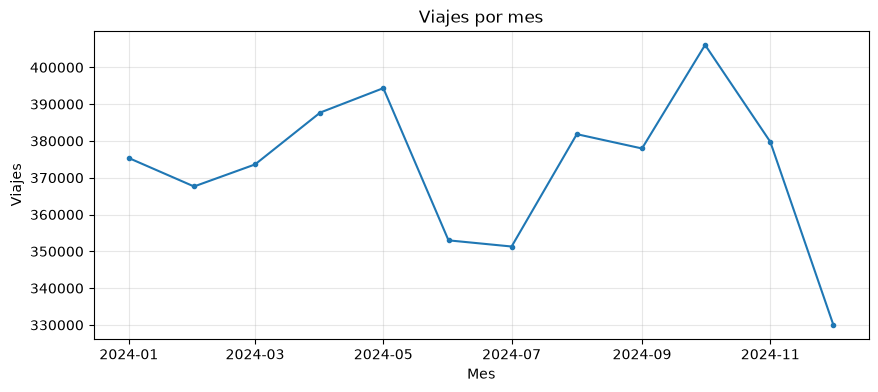

In [2]:
plots.plot_monthly_trend(trips);

## 2. Patrones por hora y día
¿Hay picos de entrada/salida al trabajo entre semana?

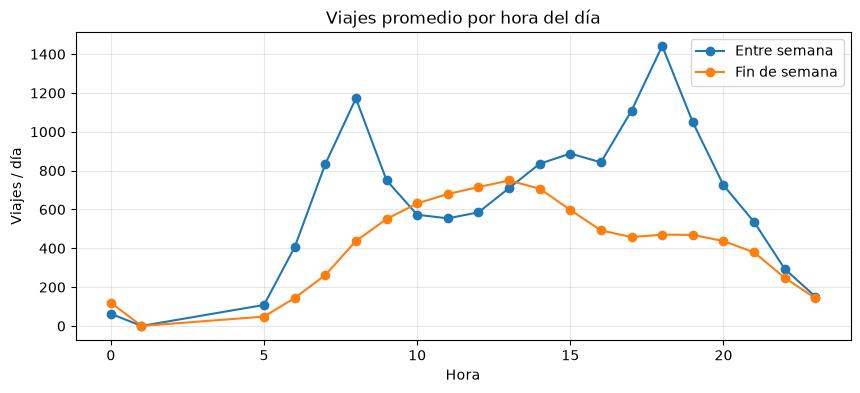

In [3]:
plots.plot_demand_by_hour(trips);

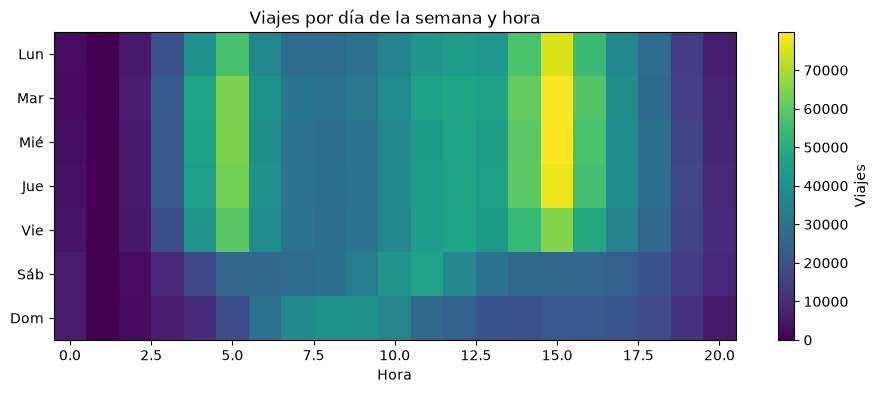

In [4]:
plots.plot_heatmap_day_hour(trips);

## 3. Duración, estaciones y usuarios

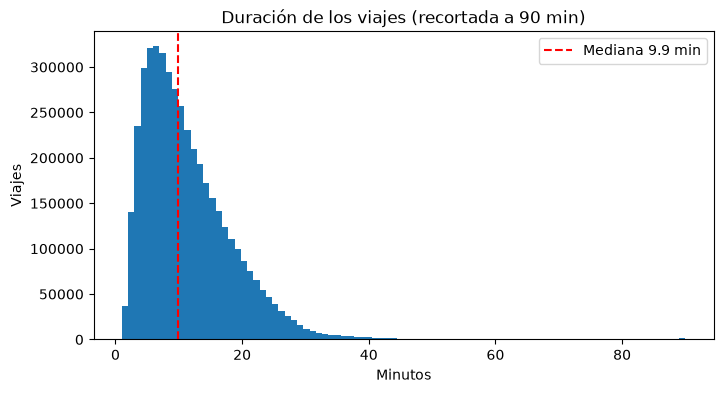

In [5]:
plots.plot_duration_distribution(trips);

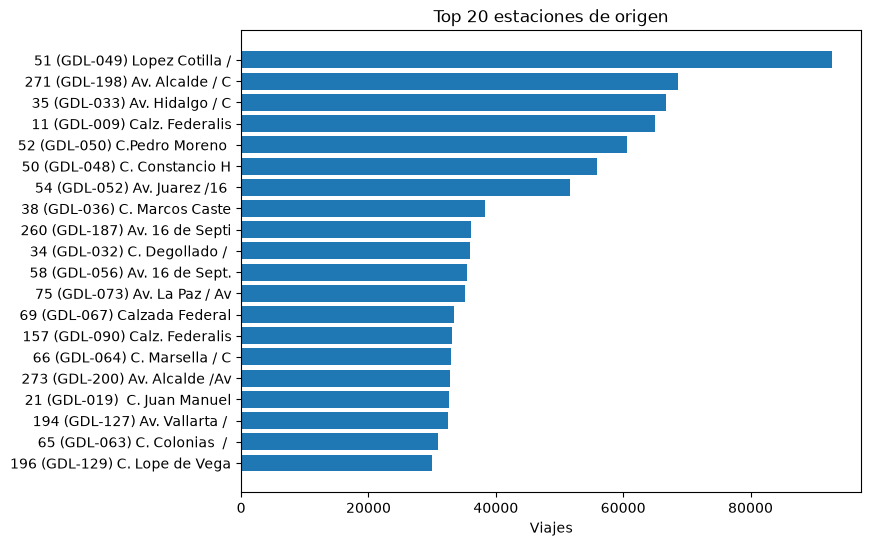

In [6]:
plots.plot_top_stations(trips, stations);

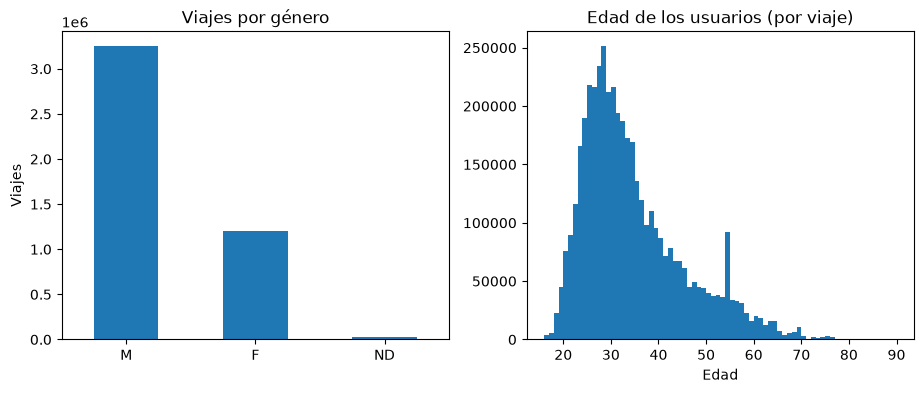

In [7]:
plots.plot_demographics(trips);

## 4. Variable objetivo: salidas por estación y hora
Se agregan los viajes y se añaden variables de calendario, rezagos y ubicación.

In [8]:
from mibici_demand.features import build_features, temporal_split, transform_split

features = build_features(trips[["start_time", "origin_id"]], stations)
features.head()

,station_id,timestamp,departures,hour,dayofweek,month,is_weekend,is_holiday,hour_sin,hour_cos,dow_sin,dow_cos,lag_1,lag_24,lag_168,rolling_mean_24,latitude,longitude
0,2,2024-01-08 08:00:00,12,8,0,1,0,0,8.660254e-01,-0.500000,0.0,1.0,8.0,1.0,1.0,1.958333,20.666378,-103.34882
1,2,2024-01-08 09:00:00,11,9,0,1,0,0,7.071068e-01,-0.707107,0.0,1.0,12.0,3.0,1.0,2.416667,20.666378,-103.34882
2,2,2024-01-08 10:00:00,4,10,0,1,0,0,5.000000e-01,-0.866025,0.0,1.0,11.0,1.0,2.0,2.750000,20.666378,-103.34882
3,2,2024-01-08 11:00:00,5,11,0,1,0,0,2.588190e-01,-0.965926,0.0,1.0,4.0,3.0,0.0,2.875000,20.666378,-103.34882
4,2,2024-01-08 12:00:00,0,12,0,1,0,0,1.224647e-16,-1.000000,0.0,1.0,5.0,0.0,2.0,2.958333,20.666378,-103.34882


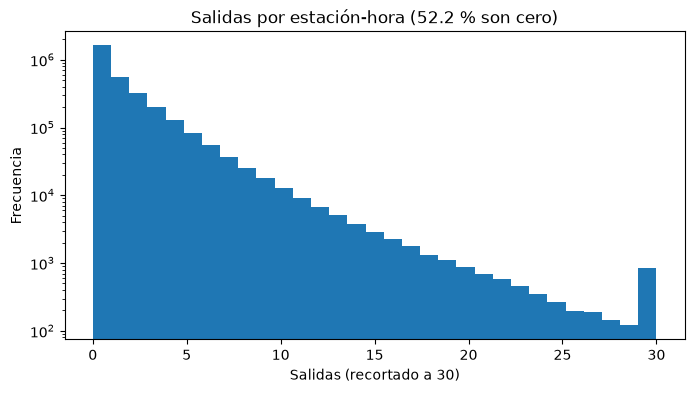

In [9]:
plots.plot_demand_distribution(features);

In [10]:
features[["departures", "lag_1", "lag_24", "lag_168", "rolling_mean_24"]].corr()["departures"]

departures         1.000000
lag_1              0.660080
lag_24             0.673137
lag_168            0.743791
rolling_mean_24    0.526506
Name: departures, dtype: float64

## 5. Preprocesamiento
- Split **temporal** (último 20 % como test) para no usar el futuro.
- `StandardScaler` en rezagos y coordenadas, one-hot del mes, codificación cíclica de
  hora/día, y `TargetEncoder` para la estación (one-hot de ~370 estaciones no cabe en memoria).
- El preprocesador se ajusta **solo con train**.

In [11]:
train, test = temporal_split(features, FEATURE_PARAMS["test_fraction"])
train_t, test_t, preprocessor = transform_split(train, test)
print(train_t.shape, test_t.shape)
train_t.describe().T.round(2)

C:\Users\Sam\Downloads\mibici-demand-main\mibici-demand-main\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


(2482903, 26) (625551, 26)


,count,mean,min,25%,50%,75%,max,std
station_id,2482903.0,197.244354,2.0,96.0,199.0,293.0,390.0,112.971627
timestamp,2482903,2024-05-31 00:17:17.408872960,2024-01-08 00:00:00,2024-03-20 08:00:00,2024-05-31 04:00:00,2024-08-10 17:00:00,2024-10-21 03:00:00,NaN
x_lag_1,2482903.0,0.0,-0.567827,-0.567827,-0.567827,0.226079,31.982319,1.0
x_lag_24,2482903.0,-0.0,-0.567776,-0.567776,-0.567776,0.226136,31.982583,1.0
x_lag_168,2482903.0,-0.0,-0.566258,-0.566258,-0.566258,0.23184,32.155736,1.0
x_rolling_mean_24,2482903.0,-0.0,-1.014636,-0.659953,-0.305271,0.374537,10.010076,1.0
x_latitude,2482903.0,0.0,-1.989312,-0.60272,-0.194187,0.44575,2.697448,1.0
x_longitude,2482903.0,0.0,-2.314008,-0.757654,0.023484,0.645915,2.255809,1.0
x_month_1,2482903.0,0.081749,0.0,0.0,0.0,0.0,1.0,0.273983
x_month_2,2482903.0,0.100914,0.0,0.0,0.0,0.0,1.0,0.301215


## 6. Reducción de dimensionalidad: PCA de perfiles de estación
Cada estación se describe por su demanda media en las 168 horas de la semana.

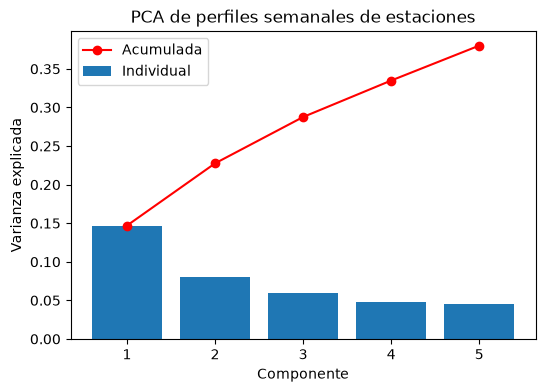

In [12]:
from mibici_demand.features import station_profiles_pca

scores, pca, profiles = station_profiles_pca(features, FEATURE_PARAMS["pca_components"])
plots.plot_pca_variance(pca);

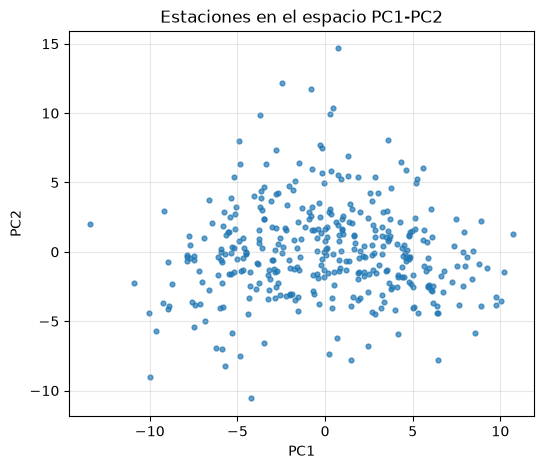

In [13]:
plots.plot_pca_stations(scores);

## Conclusiones del EDA (2024: 4,478,552 viajes limpios, 370 estaciones con viajes)

1. **Patrón de traslado al trabajo.** Entre semana hay dos picos claros, alrededor de las 8 h
   y de las 18 h. En fin de semana la demanda es más plana, con un máximo al mediodía.
   Por eso la hora, el día y el indicador de fin de semana son variables clave.
2. **Horario de operación.** Prácticamente no hay viajes entre las 2 y las 4 h; esas horas
   forman parte del 52.2 % de registros estación-hora con demanda cero.
3. **Estacionalidad mensual.** Los máximos de 2024 están en mayo y octubre (~395 mil y ~405 mil
   viajes) y los mínimos en junio-julio y diciembre (~330 mil en diciembre). Una posible
   explicación son lluvias y periodos vacacionales; no se verificó con datos externos.
4. **Demanda concentrada.** La estación más usada (51, López Cotilla) tiene ~92 mil salidas en
   el año, cerca de 35 % más que la segunda (~68 mil). Pocas estaciones concentran mucha demanda, lo que
   justifica priorizarlas en la redistribución.
5. **Viajes cortos.** La mediana de duración es de 9.9 min; casi todos los viajes duran menos de 40 min.
6. **Usuarios.** 73 % de los viajes son de hombres; la edad más frecuente está entre 25 y 35 años.
   Hay un pico aislado cerca de los 55 años que podría ser un año de nacimiento capturado por omisión;
   no afecta la demanda, pero conviene revisarlo.
7. **Historia reciente como predictor.** La demanda de la misma hora una semana antes (`lag_168`)
   es la variable más correlacionada (0.74), por encima de la de un día antes (0.67) y la de una hora
   antes (0.66): el patrón semanal es el más estable.
8. **PCA de perfiles de estación.** Los 5 primeros componentes explican 38 % de la varianza
   (PC1: 14.7 %). En el plano PC1-PC2 no hay grupos separados con claridad: los perfiles varían de
   forma continua. Para la Fase 2 conviene usar los componentes como variables adicionales, no
   como sustituto de las originales.
9. **Preprocesamiento.** Split temporal: 2,482,903 filas de entrenamiento y 625,551 de prueba.
   Las variables numéricas quedan estandarizadas (media 0) con estadísticas solo de entrenamiento.

_Revisar y ajustar estas conclusiones después de volver a ejecutar las gráficas por hora
(se corrigió un error en el eje X del mapa de calor)._